<center><h1>Xu_Yilong_HW6</h1></center>

Name: Yilong Xu
<br>
Github Username: yilongxu-usc
<br>
USC ID: 9633003204

## 1. Tree-Based Methods

Import packages

In [1]:
import pandas as pd

### (a) Download the APS Failure data

In [2]:
# Load the training and test datasets.
# The first 20 lines contain dataset information, not the CSV header.
train_data = pd.read_csv(
    "../data/aps_failure_training_set.csv", skiprows=20, na_values="na"
)
test_data = pd.read_csv(
    "../data/aps_failure_test_set.csv", skiprows=20, na_values="na"
)

print("Training set shape:", train_data.shape)
print("Test set shape:", test_data.shape)

print("\nTraining data (first 5 rows):")
display(train_data.head())

print("\nTest data (first 5 rows):")
display(test_data.head())

Training set shape: (60000, 171)
Test set shape: (16000, 171)

Training data (first 5 rows):


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0



Test data (first 5 rows):


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,60,0.0,20.0,12.0,0.0,0.0,0.0,0.0,0.0,...,1098.0,138.0,412.0,654.0,78.0,88.0,0.0,0.0,0.0,0.0
1,neg,82,0.0,68.0,40.0,0.0,0.0,0.0,0.0,0.0,...,1068.0,276.0,1620.0,116.0,86.0,462.0,0.0,0.0,0.0,0.0
2,neg,66002,2.0,212.0,112.0,0.0,0.0,0.0,0.0,0.0,...,495076.0,380368.0,440134.0,269556.0,1315022.0,153680.0,516.0,0.0,0.0,0.0
3,neg,59816,NaN,1010.0,936.0,0.0,0.0,0.0,0.0,0.0,...,540820.0,243270.0,483302.0,485332.0,431376.0,210074.0,281662.0,3232.0,0.0,0.0
4,neg,1814,NaN,156.0,140.0,0.0,0.0,0.0,0.0,0.0,...,7646.0,4144.0,18466.0,49782.0,3176.0,482.0,76.0,0.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common methods for handling missing values include deleting rows or columns with missing values, mean or median imputation, KNN imputation, and regression-based imputation.

For this dataset, I chose median imputation because all 170 features are numerical and some features may contain extreme values. The median is less sensitive to outliers than the mean. Since the dataset has many missing values, removing incomplete rows would result in losing useful information.


In [3]:
from sklearn.impute import SimpleImputer

# Separate features and class labels
X_train = train_data.drop(columns=["class"])
y_train = train_data["class"]

X_test = test_data.drop(columns=["class"])
y_test = test_data["class"]

# Check missing values before imputation
print("Missing values in training set:", X_train.isna().sum().sum())
print("Missing values in test set:", X_test.isna().sum().sum())

# Apply median imputation
imputer = SimpleImputer(strategy="median")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns
)

X_test = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns
)

# Check missing values after imputation
print("\nAfter imputation:")
print("Missing values in training set:", X_train.isna().sum().sum())
print("Missing values in test set:", X_test.isna().sum().sum())

Missing values in training set: 850015
Missing values in test set: 228680

After imputation:
Missing values in training set: 0
Missing values in test set: 0


#### (ii) Calculate the coefficient of variation

In [4]:
# Calculate the coefficient of variation for all 170 features
feature_means = X_train.mean()
feature_stds = X_train.std(ddof=1)

cv = feature_stds / feature_means

# Sort the CV values in descending order
cv_sorted = cv.sort_values(ascending=False)

# Display the CV values for all features
cv_table = pd.DataFrame({
    "Feature": cv_sorted.index,
    "CV": cv_sorted.values
})

print("Coefficient of Variation for all 170 features:")
display(cv_table)

Coefficient of Variation for all 170 features:


,Feature,CV
0,cf_000,244.887517
1,co_000,244.507385
2,ad_000,244.322816
3,cs_009,237.930554
4,dh_000,123.216097
...,...,...
165,bo_000,0.792383
166,bp_000,0.753392
167,bq_000,0.718534
168,br_000,0.689112


#### (iii) Plot a correlation matrix

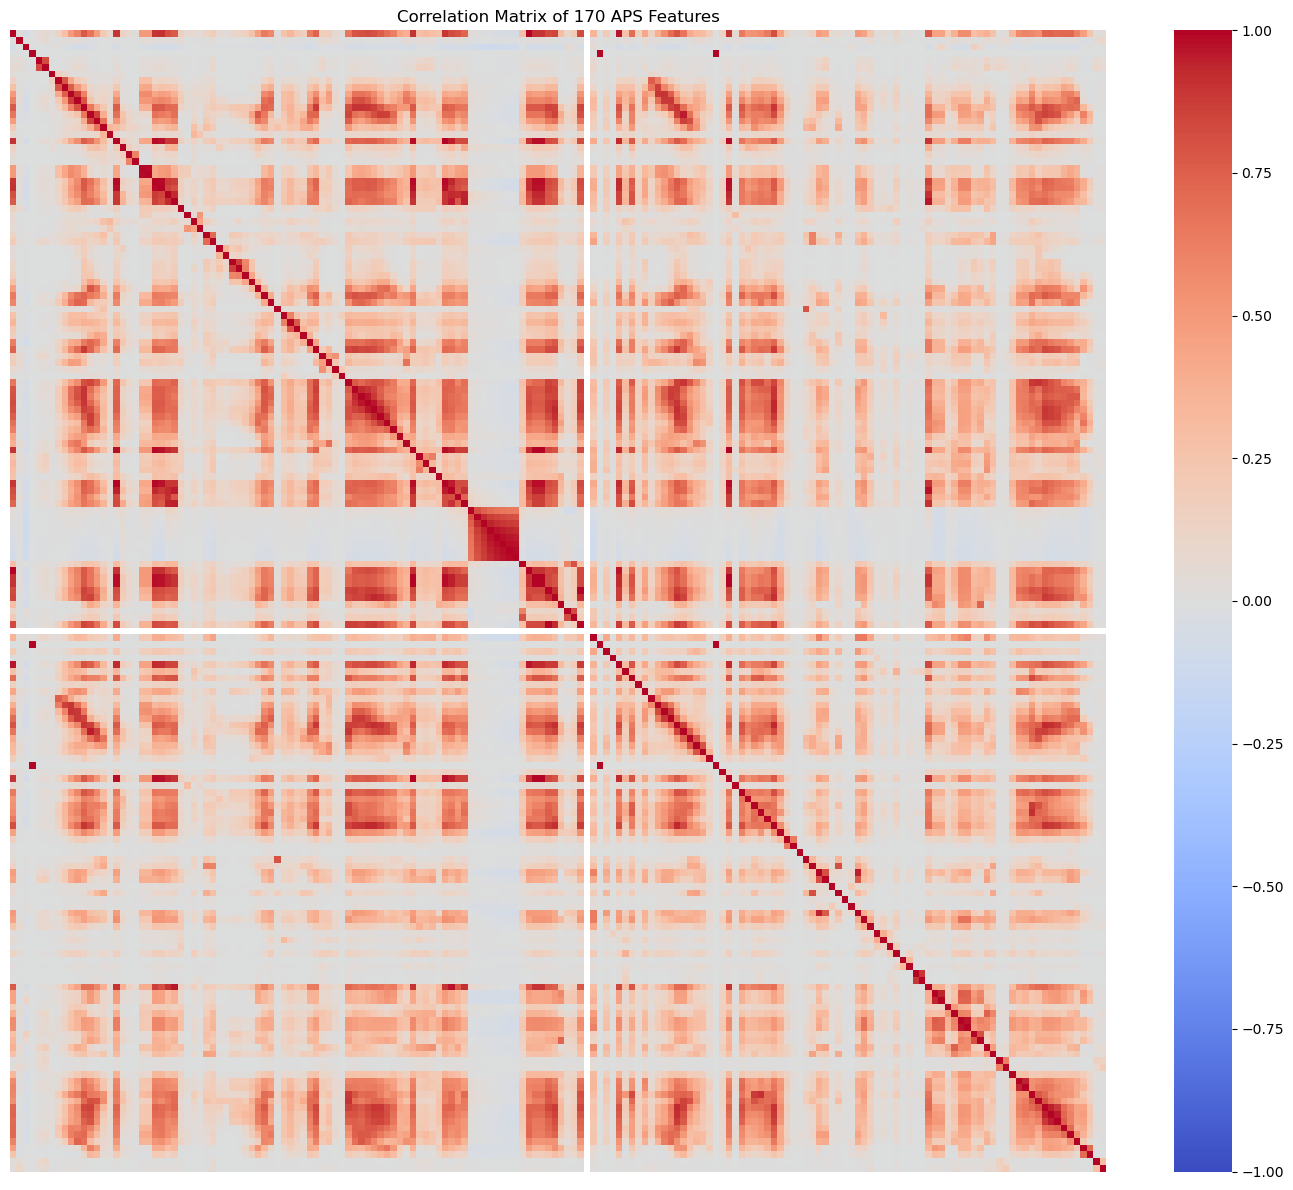

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate the correlation matrix for all 170 features
corr_matrix = X_train.corr()

# Plot the correlation matrix
plt.figure(figsize=(14, 12))

sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Matrix of 170 APS Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

Top 13 features with highest CV:
['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']


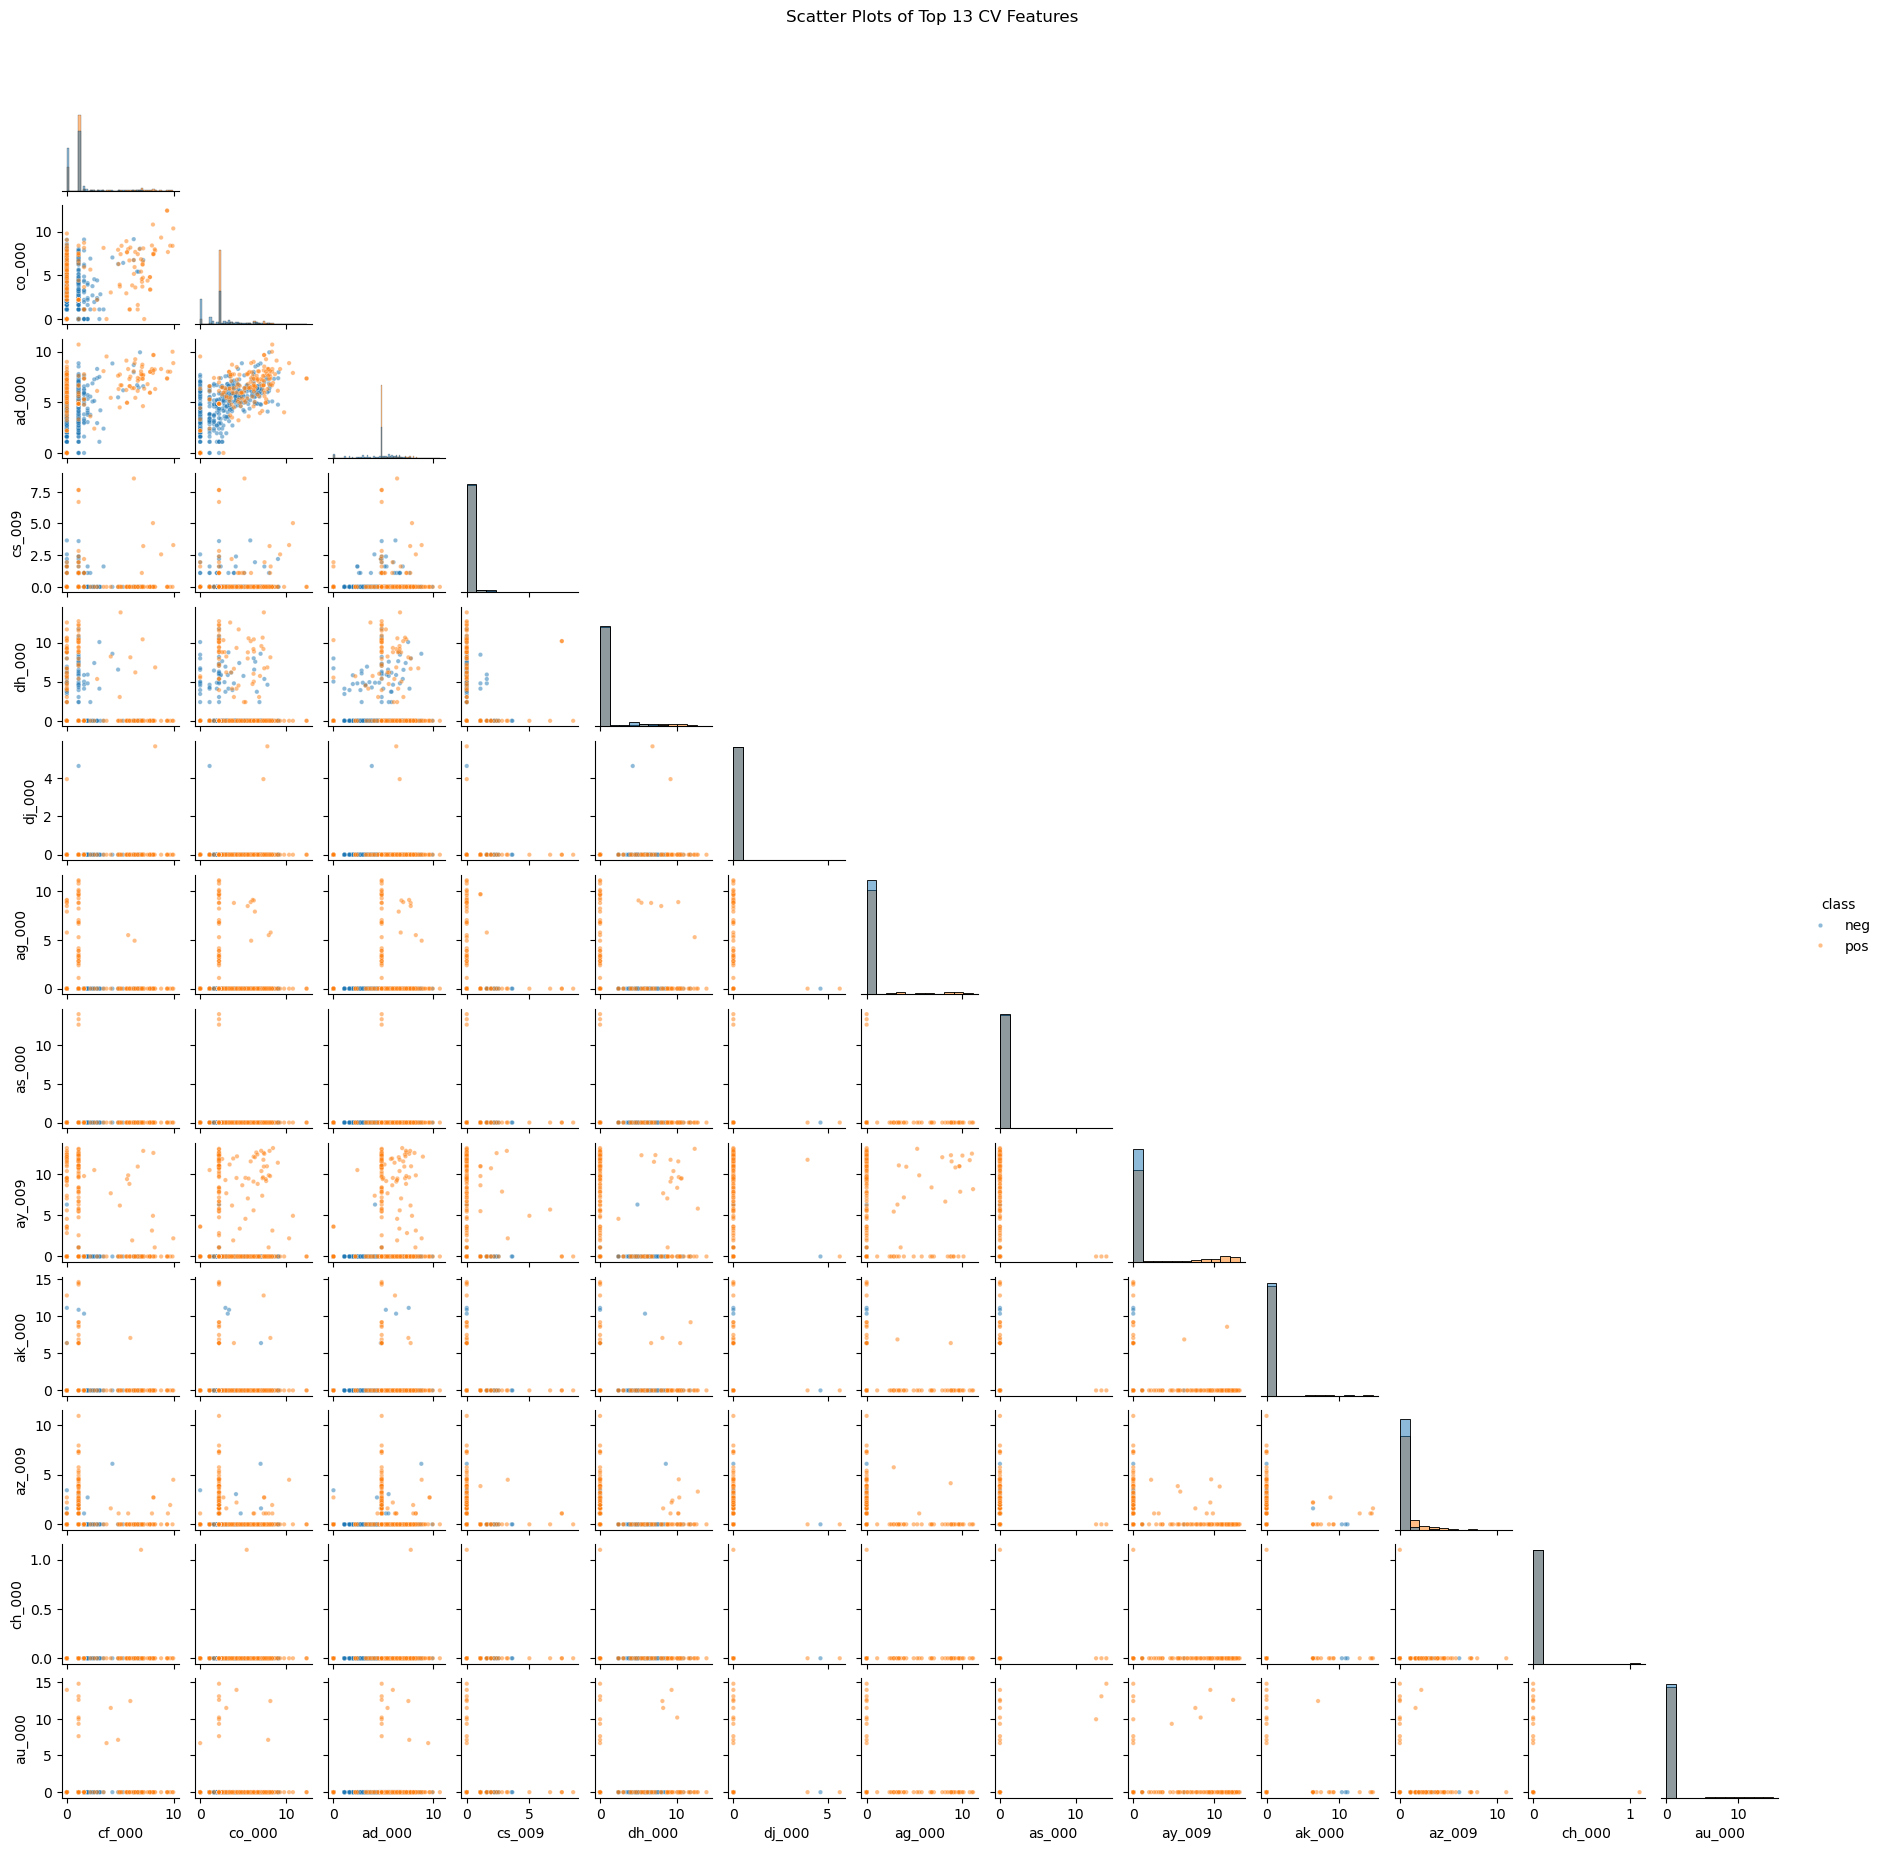

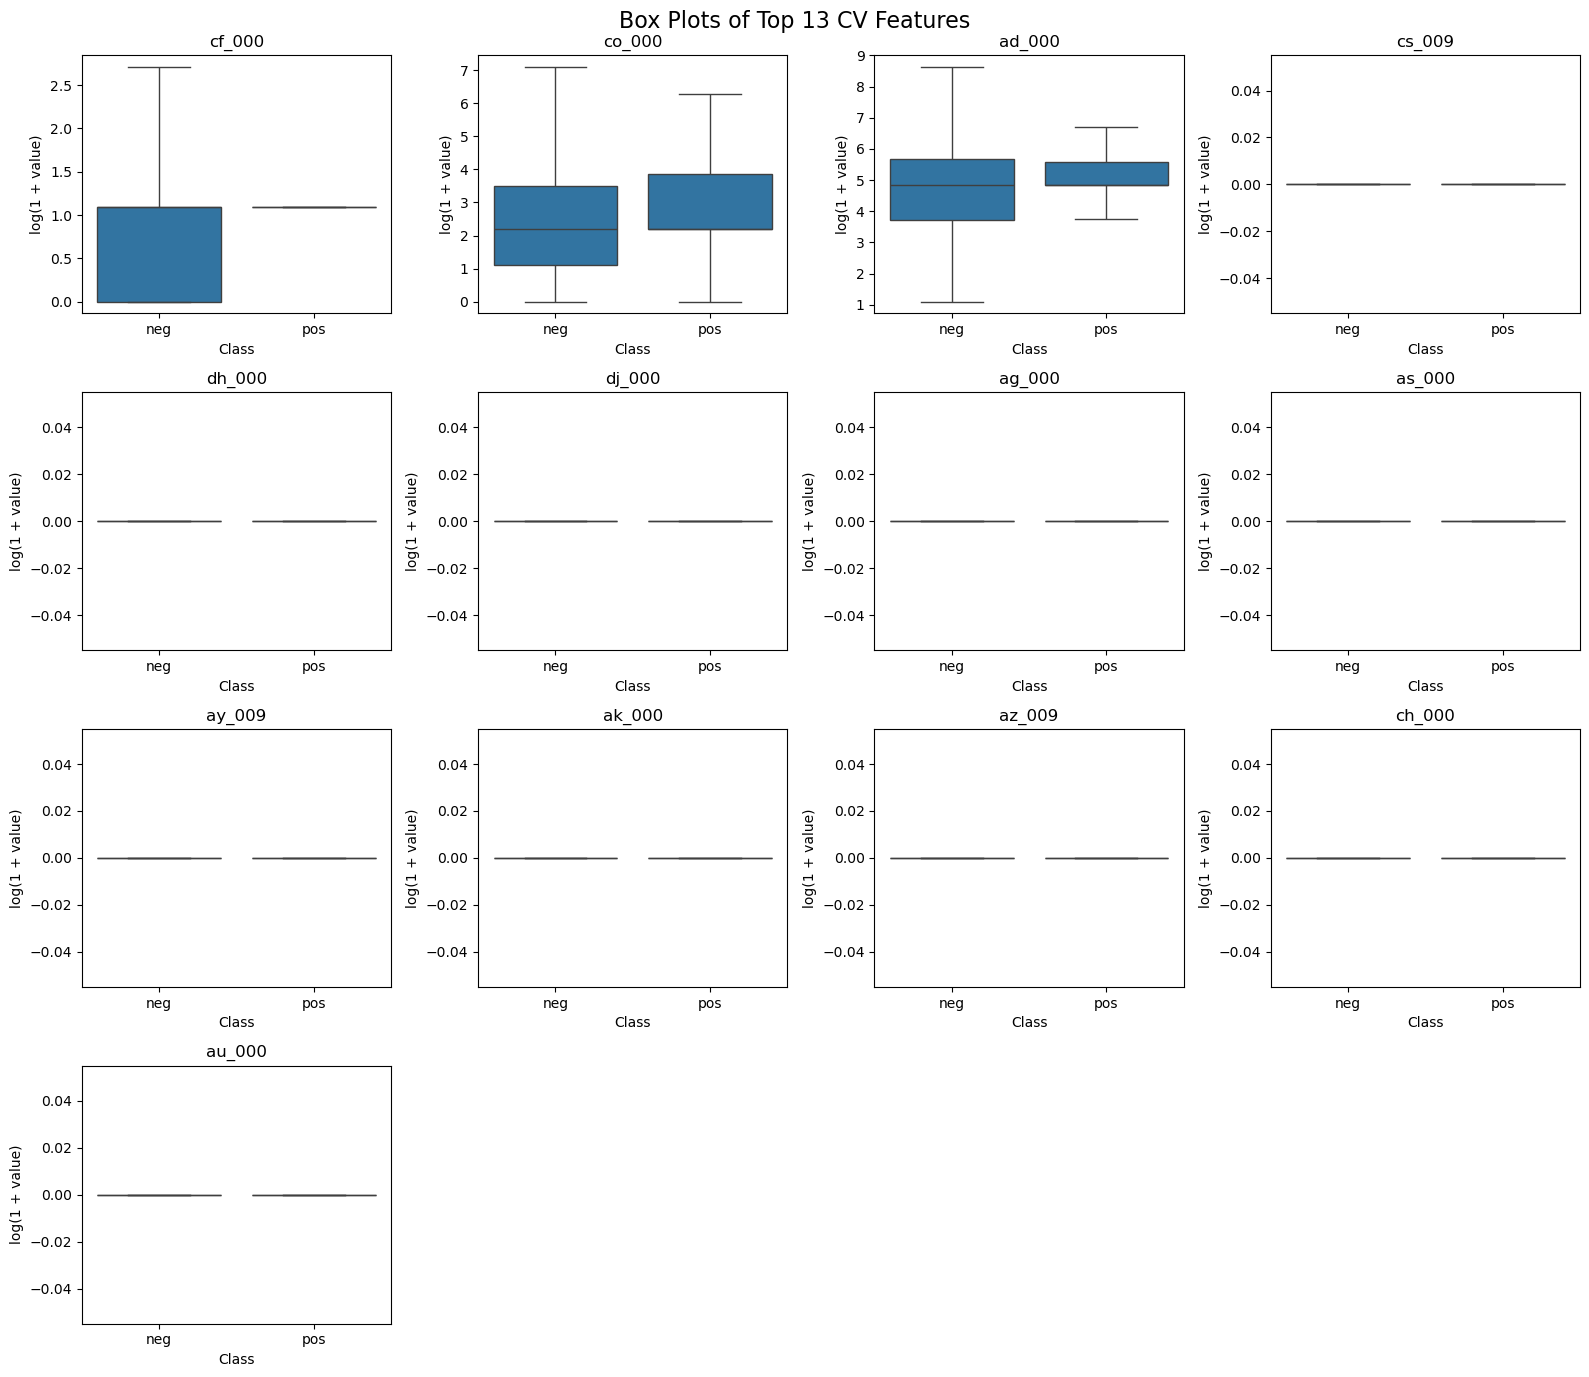

In [6]:
# Select the 13 features with the highest CV
import numpy as np

n_features = int(np.sqrt(X_train.shape[1]))
top_features = cv_sorted.head(n_features).index.tolist()

print("Top", n_features, "features with highest CV:")
print(top_features)

# Prepare data for visualization
plot_data = X_train[top_features].copy()
plot_data["class"] = y_train.values

# Sample 500 observations from each class for scatter plots
sample_data = pd.concat([
    plot_data[plot_data["class"] == "neg"].sample(500, random_state=42),
    plot_data[plot_data["class"] == "pos"].sample(500, random_state=42)
])

# Log transformation for better visualization
sample_data[top_features] = np.log1p(sample_data[top_features])

# Scatter plot matrix
sns.pairplot(
    sample_data,
    vars=top_features,
    hue="class",
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.5, "s": 10},
    height=1.4
)

plt.suptitle("Scatter Plots of Top 13 CV Features", y=1.02)
plt.show()

# Box plots using the full training dataset
box_data = plot_data.copy()
box_data[top_features] = np.log1p(box_data[top_features])

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()

for i, feature in enumerate(top_features):
    sns.boxplot(
        data=box_data,
        x="class",
        y=feature,
        order=["neg", "pos"],
        showfliers=False,
        ax=axes[i]
    )
    axes[i].set_title(feature)
    axes[i].set_xlabel("Class")
    axes[i].set_ylabel("log(1 + value)")

for j in range(len(top_features), len(axes)):
    axes[j].axis("off")

plt.suptitle("Box Plots of Top 13 CV Features", fontsize=16)
plt.tight_layout()
plt.show()

**Can we draw conclusions about the significance of these features just from the scatter plots?**

No, we cannot determine the statistical significance of these features based only on scatter plots. The plots help us visually identify possible relationships, patterns, and differences between the positive and negative classes. However, some features have highly skewed distributions and many zero values, making their relationships difficult to interpret visually. A high coefficient of variation also does not necessarily mean that a feature is important for classification. Statistical tests or predictive models are needed to evaluate their significance more reliably.

#### (v) Is this data set imbalanced?

Training Set Class Distribution:
class
neg    59000
pos     1000
Name: count, dtype: int64

Test Set Class Distribution:
class
neg    15625
pos      375
Name: count, dtype: int64

Training Set Class Percentages:
class
neg    98.33
pos     1.67
Name: proportion, dtype: float64


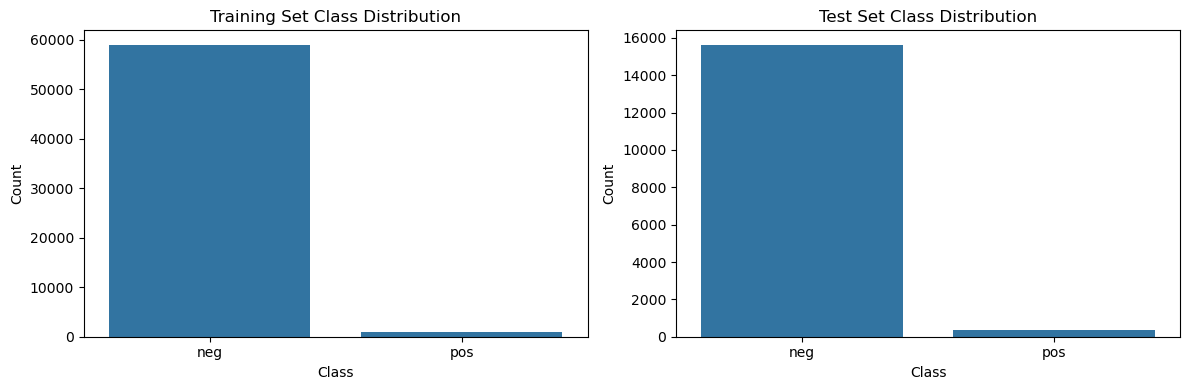

In [7]:
# Count positive and negative observations
train_counts = y_train.value_counts()
test_counts = y_test.value_counts()

print("Training Set Class Distribution:")
print(train_counts)

print("\nTest Set Class Distribution:")
print(test_counts)

# Calculate class percentages
print("\nTraining Set Class Percentages:")
print((y_train.value_counts(normalize=True) * 100).round(2))

# Visualize class imbalance
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(x=y_train, order=["neg", "pos"], ax=axes[0])
axes[0].set_title("Training Set Class Distribution")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")

sns.countplot(x=y_test, order=["neg", "pos"], ax=axes[1])
axes[1].set_title("Test Set Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

The training dataset contains 59,000 negative observations (98.33%) and 1,000 positive observations (1.67%). The test dataset contains 15,625 negative observations and 375 positive observations.

The dataset is highly imbalanced because the negative class significantly outnumbers the positive class. The ratio of negative to positive observations in the training set is 59:1.

### (c) Train a random forest

Training Confusion Matrix:


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,1,999


Test Confusion Matrix:


,Predicted neg,Predicted pos
Actual neg,15610,15
Actual pos,106,269


Training Misclassification Rate: 0.0000
Test Misclassification Rate: 0.0076
OOB Error: 0.0062
Training AUC: 1.0000
Test AUC: 0.9927
Difference between OOB and Test Error: 0.0014


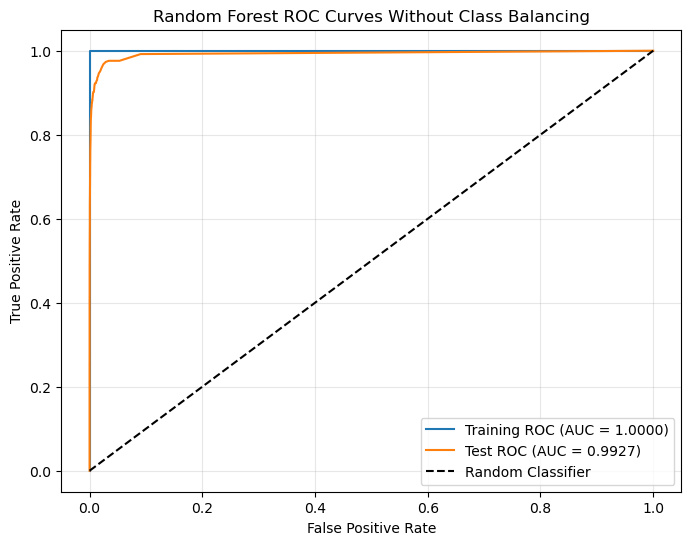

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    accuracy_score
)

# Train Random Forest without class imbalance compensation
rf = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

# Predictions
y_train_pred = rf.predict(X_train)
y_test_pred = rf.predict(X_test)

# Predicted probabilities for the positive class
pos_index = list(rf.classes_).index("pos")

y_train_prob = rf.predict_proba(X_train)[:, pos_index]
y_test_prob = rf.predict_proba(X_test)[:, pos_index]

# Confusion matrices
train_cm = confusion_matrix(
    y_train, y_train_pred, labels=["neg", "pos"]
)
test_cm = confusion_matrix(
    y_test, y_test_pred, labels=["neg", "pos"]
)

print("Training Confusion Matrix:")
display(pd.DataFrame(
    train_cm,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

print("Test Confusion Matrix:")
display(pd.DataFrame(
    test_cm,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

# Misclassification rates
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)

# Out-of-Bag error
oob_error = 1 - rf.oob_score_

# AUC scores
train_auc = roc_auc_score(y_train == "pos", y_train_prob)
test_auc = roc_auc_score(y_test == "pos", y_test_prob)

print(f"Training Misclassification Rate: {train_error:.4f}")
print(f"Test Misclassification Rate: {test_error:.4f}")
print(f"OOB Error: {oob_error:.4f}")
print(f"Training AUC: {train_auc:.4f}")
print(f"Test AUC: {test_auc:.4f}")
print(f"Difference between OOB and Test Error: {abs(oob_error - test_error):.4f}")

# ROC curves
fpr_train, tpr_train, _ = roc_curve(
    y_train, y_train_prob, pos_label="pos"
)
fpr_test, tpr_test, _ = roc_curve(
    y_test, y_test_prob, pos_label="pos"
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train, tpr_train,
    label=f"Training ROC (AUC = {train_auc:.4f})"
)
plt.plot(
    fpr_test, tpr_test,
    label=f"Test ROC (AUC = {test_auc:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves Without Class Balancing")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

A Random Forest classifier with 100 trees was trained without class imbalance compensation. The model used all 170 numerical features after median imputation.

The confusion matrices, misclassification rates, and AUC scores were calculated for both the training and test sets. ROC curves were plotted to compare classification performance.

The Out-of-Bag error was also calculated and compared with the test error. Since the dataset is highly imbalanced, the confusion matrices and AUC scores are important for evaluating performance beyond overall accuracy.

### (d) Research class imbalance in random forest

Class imbalance in Random Forests can be addressed using several methods, including oversampling the minority class, undersampling the majority class, and assigning different weights to each class.

In this question, I use class weighting to address the imbalance. The `balanced_subsample` option in scikit-learn automatically calculates class weights based on the class frequencies in each tree's bootstrap sample. This gives more importance to the minority class during model training.

The model uses the same parameters as Question 1(c), except for the class weighting, so the results can be compared directly.

Reference: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

Training Confusion Matrix:


,Predicted neg,Predicted pos
Actual neg,59000,0
Actual pos,1,999


Test Confusion Matrix:


,Predicted neg,Predicted pos
Actual neg,15612,13
Actual pos,159,216


Training Misclassification Rate: 0.0000
Test Misclassification Rate: 0.0108
OOB Error: 0.0079
Training AUC: 1.0000
Test AUC: 0.9907
Difference between OOB and Test Error: 0.0029


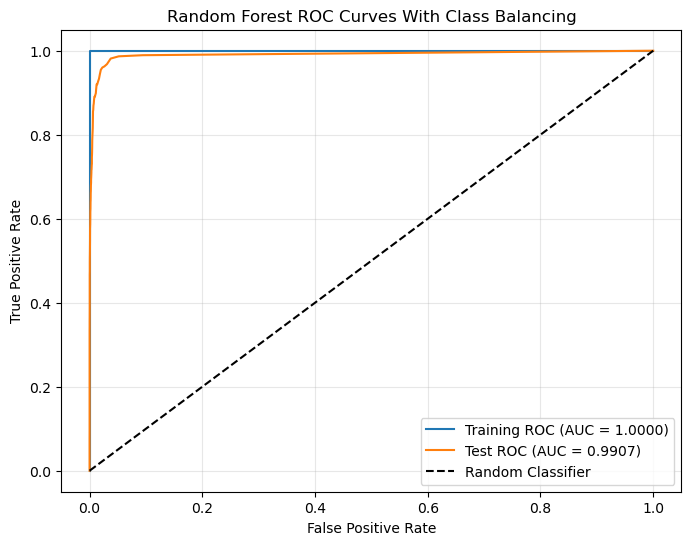

In [9]:
# Random Forest with class imbalance compensation
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    oob_score=True,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

rf_balanced.fit(X_train, y_train)

# Predictions
y_train_pred_bal = rf_balanced.predict(X_train)
y_test_pred_bal = rf_balanced.predict(X_test)

# Predicted probabilities
pos_index_bal = list(rf_balanced.classes_).index("pos")

y_train_prob_bal = rf_balanced.predict_proba(X_train)[:, pos_index_bal]
y_test_prob_bal = rf_balanced.predict_proba(X_test)[:, pos_index_bal]

# Confusion matrices
train_cm_bal = confusion_matrix(
    y_train, y_train_pred_bal, labels=["neg", "pos"]
)
test_cm_bal = confusion_matrix(
    y_test, y_test_pred_bal, labels=["neg", "pos"]
)

print("Training Confusion Matrix:")
display(pd.DataFrame(
    train_cm_bal,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

print("Test Confusion Matrix:")
display(pd.DataFrame(
    test_cm_bal,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

# Misclassification rates
train_error_bal = 1 - accuracy_score(y_train, y_train_pred_bal)
test_error_bal = 1 - accuracy_score(y_test, y_test_pred_bal)

# Out-of-Bag error
oob_error_bal = 1 - rf_balanced.oob_score_

# AUC scores
train_auc_bal = roc_auc_score(y_train == "pos", y_train_prob_bal)
test_auc_bal = roc_auc_score(y_test == "pos", y_test_prob_bal)

print(f"Training Misclassification Rate: {train_error_bal:.4f}")
print(f"Test Misclassification Rate: {test_error_bal:.4f}")
print(f"OOB Error: {oob_error_bal:.4f}")
print(f"Training AUC: {train_auc_bal:.4f}")
print(f"Test AUC: {test_auc_bal:.4f}")
print(f"Difference between OOB and Test Error: {abs(oob_error_bal - test_error_bal):.4f}")

# ROC curves
fpr_train_bal, tpr_train_bal, _ = roc_curve(
    y_train, y_train_prob_bal, pos_label="pos"
)
fpr_test_bal, tpr_test_bal, _ = roc_curve(
    y_test, y_test_prob_bal, pos_label="pos"
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train_bal, tpr_train_bal,
    label=f"Training ROC (AUC = {train_auc_bal:.4f})"
)
plt.plot(
    fpr_test_bal, tpr_test_bal,
    label=f"Test ROC (AUC = {test_auc_bal:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves With Class Balancing")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

,Metric,Without Balancing,With Balancing
0,Training Error,0.0000,0.0000
1,Test Error,0.0076,0.0108
2,OOB Error,0.0062,0.0079
3,Training AUC,1.0000,1.0000
4,Test AUC,0.9927,0.9907
5,Test False Positives,15.0000,13.0000
6,Test False Negatives,106.0000,159.0000


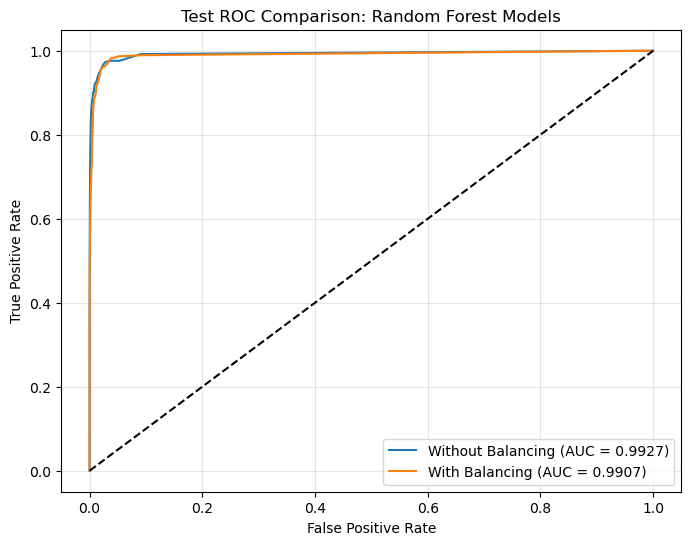

In [10]:
# Compare Random Forest models
comparison = pd.DataFrame({
    "Metric": [
        "Training Error",
        "Test Error",
        "OOB Error",
        "Training AUC",
        "Test AUC",
        "Test False Positives",
        "Test False Negatives"
    ],
    "Without Balancing": [
        train_error,
        test_error,
        oob_error,
        train_auc,
        test_auc,
        test_cm[0, 1],
        test_cm[1, 0]
    ],
    "With Balancing": [
        train_error_bal,
        test_error_bal,
        oob_error_bal,
        train_auc_bal,
        test_auc_bal,
        test_cm_bal[0, 1],
        test_cm_bal[1, 0]
    ]
})

display(comparison.round(4))

# Compare test ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_test, tpr_test,
    label=f"Without Balancing (AUC = {test_auc:.4f})"
)

plt.plot(
    fpr_test_bal, tpr_test_bal,
    label=f"With Balancing (AUC = {test_auc_bal:.4f})"
)

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Test ROC Comparison: Random Forest Models")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Comparison of Random Forest Models**

The Random Forest without class balancing performed slightly better than the balanced model. Its test error was 0.0076, compared to 0.0108 for the balanced model. The test AUC was also slightly higher without balancing (0.9927 vs. 0.9907).

Both models achieved zero training error and a training AUC of 1.0, which suggests that they fit the training data very closely. The OOB errors were 0.0062 and 0.0079, respectively, which were reasonably close to the corresponding test errors.

After applying class balancing, false positives decreased from 15 to 13, but false negatives increased from 106 to 159. This means the balanced model missed more actual APS failures, which is particularly undesirable in this application.

Overall, class balancing did not improve performance in this experiment. The unbalanced Random Forest achieved a lower test error, a slightly higher AUC, and fewer false negatives.


### (e) XGBoost and Model Trees

In [11]:
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Convert class labels to binary values
y_train_xgb = (y_train == "pos").astype(int)
y_test_xgb = (y_test == "pos").astype(int)

# Use the original feature data for cross-validation
X_train_raw = train_data.drop(columns=["class"])
X_test_raw = test_data.drop(columns=["class"])

# XGBoost model without class imbalance compensation
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        scale_pos_weight=1,
        random_state=42,
        n_jobs=4
    ))
])

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Tune L1 regularization parameter alpha
param_grid = {
    "xgb__reg_alpha": [0, 0.1, 1, 10]
}

grid_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=param_grid,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    refit="roc_auc",
    cv=cv,
    n_jobs=1
)

grid_search.fit(X_train_raw, y_train_xgb)

# Best alpha
best_alpha = grid_search.best_params_["xgb__reg_alpha"]
best_index = grid_search.best_index_

# Cross-validation results
cv_auc = grid_search.best_score_
cv_error = 1 - grid_search.cv_results_[
    "mean_test_accuracy"
][best_index]

print(f"Best Alpha: {best_alpha}")
print(f"5-Fold CV AUC: {cv_auc:.4f}")
print(f"5-Fold CV Error: {cv_error:.4f}")

# Display results for all alpha values
cv_results = pd.DataFrame({
    "Alpha": grid_search.cv_results_["param_xgb__reg_alpha"],
    "CV AUC": grid_search.cv_results_["mean_test_roc_auc"],
    "CV Error": 1 - grid_search.cv_results_["mean_test_accuracy"]
})

display(cv_results.round(4))

Best Alpha: 10
5-Fold CV AUC: 0.9894
5-Fold CV Error: 0.0075


,Alpha,CV AUC,CV Error
0,0.0,0.9891,0.0066
1,0.1,0.9892,0.0064
2,1.0,0.9882,0.0065
3,10.0,0.9894,0.0075


Training Confusion Matrix:


,Predicted neg,Predicted pos
Actual neg,58942,58
Actual pos,205,795


Test Confusion Matrix:


,Predicted neg,Predicted pos
Actual neg,15598,27
Actual pos,110,265


Training Error: 0.0044
Test Error: 0.0086
5-Fold CV Error: 0.0075
Training AUC: 0.9961
Test AUC: 0.9953
CV and Test Error Difference: 0.0011


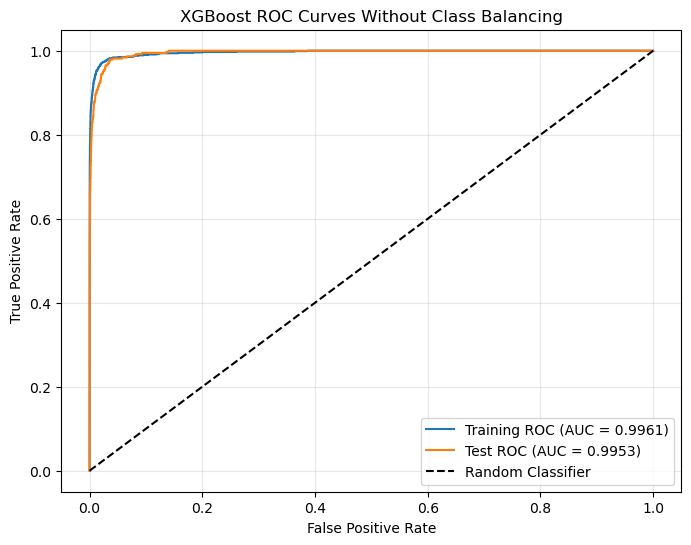

In [12]:
# Best XGBoost model
best_xgb = grid_search.best_estimator_

# Predictions
y_train_pred_xgb = best_xgb.predict(X_train_raw)
y_test_pred_xgb = best_xgb.predict(X_test_raw)

# Predicted probabilities
y_train_prob_xgb = best_xgb.predict_proba(X_train_raw)[:, 1]
y_test_prob_xgb = best_xgb.predict_proba(X_test_raw)[:, 1]

# Confusion matrices
train_cm_xgb = confusion_matrix(
    y_train_xgb, y_train_pred_xgb
)
test_cm_xgb = confusion_matrix(
    y_test_xgb, y_test_pred_xgb
)

print("Training Confusion Matrix:")
display(pd.DataFrame(
    train_cm_xgb,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

print("Test Confusion Matrix:")
display(pd.DataFrame(
    test_cm_xgb,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

# Misclassification rates
train_error_xgb = 1 - accuracy_score(
    y_train_xgb, y_train_pred_xgb
)
test_error_xgb = 1 - accuracy_score(
    y_test_xgb, y_test_pred_xgb
)

# AUC scores
train_auc_xgb = roc_auc_score(
    y_train_xgb, y_train_prob_xgb
)
test_auc_xgb = roc_auc_score(
    y_test_xgb, y_test_prob_xgb
)

print(f"Training Error: {train_error_xgb:.4f}")
print(f"Test Error: {test_error_xgb:.4f}")
print(f"5-Fold CV Error: {cv_error:.4f}")
print(f"Training AUC: {train_auc_xgb:.4f}")
print(f"Test AUC: {test_auc_xgb:.4f}")

# Compare cross-validation error with test error
print(f"CV and Test Error Difference: {abs(cv_error - test_error_xgb):.4f}")

# ROC curves
fpr_train_xgb, tpr_train_xgb, _ = roc_curve(
    y_train_xgb, y_train_prob_xgb
)
fpr_test_xgb, tpr_test_xgb, _ = roc_curve(
    y_test_xgb, y_test_prob_xgb
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train_xgb, tpr_train_xgb,
    label=f"Training ROC (AUC = {train_auc_xgb:.4f})"
)

plt.plot(
    fpr_test_xgb, tpr_test_xgb,
    label=f"Test ROC (AUC = {test_auc_xgb:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves Without Class Balancing")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### (f) Use SMOTE to pre-process your data

In [13]:
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# Create pipeline with imputation, SMOTE, and XGBoost
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("smote", SMOTE(random_state=42)),
    ("xgb", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        n_estimators=100,
        max_depth=4,
        learning_rate=0.1,
        tree_method="hist",
        scale_pos_weight=1,
        random_state=42,
        n_jobs=4
    ))
])

# Tune L1 regularization using 5-fold cross-validation
param_grid_smote = {
    "xgb__reg_alpha": [0, 0.1, 1, 10]
}

grid_search_smote = GridSearchCV(
    estimator=smote_pipeline,
    param_grid=param_grid_smote,
    scoring={
        "accuracy": "accuracy",
        "roc_auc": "roc_auc"
    },
    refit="roc_auc",
    cv=cv,
    n_jobs=1
)

# Fit using the original training features
grid_search_smote.fit(X_train_raw, y_train_xgb)

# Best parameters and CV results
best_alpha_smote = grid_search_smote.best_params_["xgb__reg_alpha"]
best_index_smote = grid_search_smote.best_index_

cv_auc_smote = grid_search_smote.best_score_
cv_error_smote = 1 - grid_search_smote.cv_results_[
    "mean_test_accuracy"
][best_index_smote]

print(f"Best Alpha: {best_alpha_smote}")
print(f"5-Fold CV AUC: {cv_auc_smote:.4f}")
print(f"5-Fold CV Error: {cv_error_smote:.4f}")

# Display cross-validation results
cv_results_smote = pd.DataFrame({
    "Alpha": grid_search_smote.cv_results_["param_xgb__reg_alpha"],
    "CV AUC": grid_search_smote.cv_results_["mean_test_roc_auc"],
    "CV Error": 1 - grid_search_smote.cv_results_["mean_test_accuracy"]
})

display(cv_results_smote.round(4))

Best Alpha: 10
5-Fold CV AUC: 0.9858
5-Fold CV Error: 0.0160


,Alpha,CV AUC,CV Error
0,0.0,0.9849,0.0157
1,0.1,0.9851,0.0151
2,1.0,0.9851,0.0156
3,10.0,0.9858,0.0160


Training Confusion Matrix:


,Predicted neg,Predicted pos
Actual neg,58161,839
Actual pos,57,943


Test Confusion Matrix:


,Predicted neg,Predicted pos
Actual neg,15411,214
Actual pos,36,339


Training Error: 0.0149
Test Error: 0.0156
5-Fold CV Error: 0.0160
Training AUC: 0.9962
Test AUC: 0.9947
CV and Test Error Difference: 0.0004


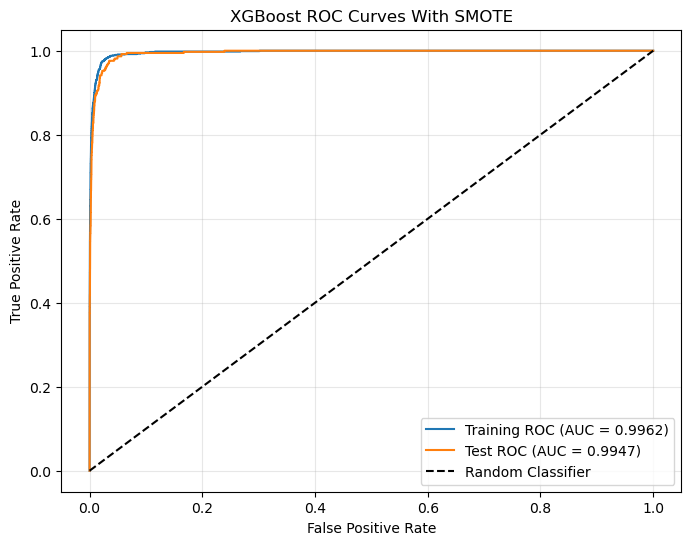

In [14]:
# Best SMOTE + XGBoost model
best_xgb_smote = grid_search_smote.best_estimator_

# Predictions
y_train_pred_smote = best_xgb_smote.predict(X_train_raw)
y_test_pred_smote = best_xgb_smote.predict(X_test_raw)

# Predicted probabilities
y_train_prob_smote = best_xgb_smote.predict_proba(X_train_raw)[:, 1]
y_test_prob_smote = best_xgb_smote.predict_proba(X_test_raw)[:, 1]

# Confusion matrices
train_cm_smote = confusion_matrix(
    y_train_xgb, y_train_pred_smote
)
test_cm_smote = confusion_matrix(
    y_test_xgb, y_test_pred_smote
)

print("Training Confusion Matrix:")
display(pd.DataFrame(
    train_cm_smote,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

print("Test Confusion Matrix:")
display(pd.DataFrame(
    test_cm_smote,
    index=["Actual neg", "Actual pos"],
    columns=["Predicted neg", "Predicted pos"]
))

# Misclassification rates
train_error_smote = 1 - accuracy_score(
    y_train_xgb, y_train_pred_smote
)
test_error_smote = 1 - accuracy_score(
    y_test_xgb, y_test_pred_smote
)

# AUC scores
train_auc_smote = roc_auc_score(
    y_train_xgb, y_train_prob_smote
)
test_auc_smote = roc_auc_score(
    y_test_xgb, y_test_prob_smote
)

print(f"Training Error: {train_error_smote:.4f}")
print(f"Test Error: {test_error_smote:.4f}")
print(f"5-Fold CV Error: {cv_error_smote:.4f}")
print(f"Training AUC: {train_auc_smote:.4f}")
print(f"Test AUC: {test_auc_smote:.4f}")

print(f"CV and Test Error Difference: {abs(cv_error_smote - test_error_smote):.4f}")

# ROC curves
fpr_train_smote, tpr_train_smote, _ = roc_curve(
    y_train_xgb, y_train_prob_smote
)
fpr_test_smote, tpr_test_smote, _ = roc_curve(
    y_test_xgb, y_test_prob_smote
)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr_train_smote, tpr_train_smote,
    label=f"Training ROC (AUC = {train_auc_smote:.4f})"
)

plt.plot(
    fpr_test_smote, tpr_test_smote,
    label=f"Test ROC (AUC = {test_auc_smote:.4f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves With SMOTE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


,Metric,Without SMOTE,With SMOTE
0,Best Alpha,10.0000,10.0000
1,Training Error,0.0044,0.0149
2,Test Error,0.0086,0.0156
3,5-Fold CV Error,0.0075,0.0160
4,Training AUC,0.9961,0.9962
5,Test AUC,0.9953,0.9947
6,Test False Positives,27.0000,214.0000
7,Test False Negatives,110.0000,36.0000


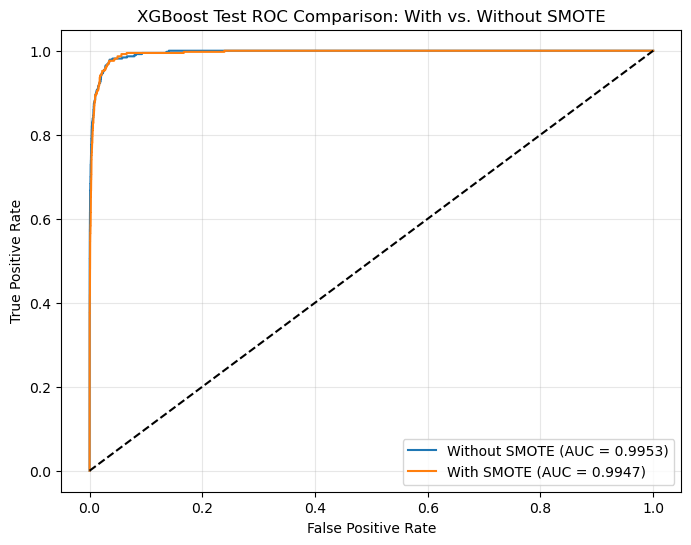

In [15]:
# Compare XGBoost models
comparison_xgb = pd.DataFrame({
    "Metric": [
        "Best Alpha",
        "Training Error",
        "Test Error",
        "5-Fold CV Error",
        "Training AUC",
        "Test AUC",
        "Test False Positives",
        "Test False Negatives"
    ],
    "Without SMOTE": [
        best_alpha,
        train_error_xgb,
        test_error_xgb,
        cv_error,
        train_auc_xgb,
        test_auc_xgb,
        test_cm_xgb[0, 1],
        test_cm_xgb[1, 0]
    ],
    "With SMOTE": [
        best_alpha_smote,
        train_error_smote,
        test_error_smote,
        cv_error_smote,
        train_auc_smote,
        test_auc_smote,
        test_cm_smote[0, 1],
        test_cm_smote[1, 0]
    ]
})

display(comparison_xgb.round(4))

# Compare test ROC curves
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_test_xgb, tpr_test_xgb,
    label=f"Without SMOTE (AUC = {test_auc_xgb:.4f})"
)

plt.plot(
    fpr_test_smote, tpr_test_smote,
    label=f"With SMOTE (AUC = {test_auc_smote:.4f})"
)

plt.plot([0, 1], [0, 1], "k--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost Test ROC Comparison: With vs. Without SMOTE")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

SMOTE was applied to address the class imbalance before training the XGBoost model. Five-fold stratified cross-validation was used to select the L1 regularization parameter. The best alpha was 10, with a cross-validation AUC of 0.9858 and an error of 0.0160.

Compared with the model without SMOTE, the test error increased from 0.0086 to 0.0156, while the test AUC decreased slightly from 0.9953 to 0.9947. However, SMOTE substantially improved the detection of positive cases. The number of false negatives decreased from 110 to 36, while false positives increased from 27 to 214. The positive-class recall improved from 70.67% to 90.40%.

This shows that SMOTE improved the model's ability to identify APS failures, although it increased the overall misclassification rate. According to the dataset description, a false negative has a cost of 500, while a false positive has a cost of 10. The total misclassification cost decreased from 55,270 without SMOTE to 20,140 with SMOTE.

Overall, SMOTE did not improve the test error or AUC, but it significantly reduced false negatives and the total misclassification cost. Therefore, the SMOTE model may be more suitable for this application, where missing an actual APS failure is much more costly than performing an unnecessary inspection.

## 2. ISLR 6.6.3

**(a) iv. Steadily decrease.**

As s increases, the constraint on the coefficients becomes less restrictive, allowing the model to fit the training data better. Therefore, the training RSS will decrease or remain unchanged.

**(b) ii. Decrease initially, and then eventually start increasing in a U shape.**

When s is small, the model is highly restricted and may underfit the data. As s increases, the test RSS initially decreases because the model becomes more flexible. However, when s becomes too large, the model may overfit the training data, causing the test RSS to increase.

**(c) iii. Steadily increase.**

As s increases, the model becomes more flexible because the coefficients are less restricted. More flexible models are generally more sensitive to variations in the training data, so the variance increases.

**(d) iv. Steadily decrease.**

When s is small, the coefficients are strongly restricted, resulting in a simpler model with higher bias. As s increases, the model becomes more flexible and can better capture the underlying relationships, so the squared bias generally decreases.

**(e) v. Remain constant.**

Irreducible error comes from random noise and other factors that cannot be explained by the predictors. It does not depend on the value of s or the flexibility of the model, so it remains constant.


## 3. ISLR 6.6.5

**(a) Ridge Regression Optimization Problem**

The ridge regression optimization problem is:

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(\beta_1^2+\beta_2^2)
$$

Since $x_{11}=x_{12}$ and $x_{21}=x_{22}$, it becomes:

$$
\min_{\beta_1,\beta_2}
\left[(y_1-x_{11}(\beta_1+\beta_2))^2+
(y_2-x_{21}(\beta_1+\beta_2))^2\right]
+\lambda(\beta_1^2+\beta_2^2)
$$

**(b) Show that $\hat{\beta}_1=\hat{\beta}_2$**

Taking the derivative with respect to $\beta_1$:

$$
-2\sum_{i=1}^{2}x_{i1}(y_i-x_{i1}(\beta_1+\beta_2))
+2\lambda\beta_1=0
$$

Taking the derivative with respect to $\beta_2$:

$$
-2\sum_{i=1}^{2}x_{i1}(y_i-x_{i1}(\beta_1+\beta_2))
+2\lambda\beta_2=0
$$

Subtracting the two equations gives:

$$
2\lambda(\beta_1-\beta_2)=0
$$

For $\lambda>0$:

$$
\boxed{\hat{\beta}_1=\hat{\beta}_2}
$$

Therefore, ridge regression assigns equal coefficients to the two identical predictors.

**(c) Lasso Regression Optimization Problem**

The lasso regression optimization problem is:

$$
\min_{\beta_1,\beta_2}
\sum_{i=1}^{2}(y_i-\beta_1x_{i1}-\beta_2x_{i2})^2
+\lambda(|\beta_1|+|\beta_2|)
$$

Since the predictors are identical, this becomes:

$$
\min_{\beta_1,\beta_2}
\left[(y_1-x_{11}(\beta_1+\beta_2))^2+
(y_2-x_{21}(\beta_1+\beta_2))^2\right]
+\lambda(|\beta_1|+|\beta_2|)
$$

**(d) Explain Why the Lasso Coefficients Are Not Unique**

Because the predictors are identical, the residual sum of squares depends only on the sum $\beta_1+\beta_2$.

Let:

$$
c=\beta_1+\beta_2
$$

For coefficients with the same sign (or one equal to zero):

$$
|\beta_1|+|\beta_2|=|\beta_1+\beta_2|=|c|
$$

Therefore, the lasso objective becomes:

$$
\sum_{i=1}^{2}(y_i-x_{i1}c)^2+\lambda|c|
$$

Suppose the optimal coefficient sum is $\hat{c}>0$. Then any pair satisfying

$$
\beta_1+\beta_2=\hat{c},\qquad
\beta_1\geq0,\quad\beta_2\geq0
$$

gives the same objective value.

For example, possible solutions include:

$$
(\hat{c},0),\quad
(0,\hat{c}),\quad
\left(\frac{\hat{c}}{2},\frac{\hat{c}}{2}\right)
$$

If $\hat{c}<0$, the same argument applies when both coefficients are nonpositive.

Thus, when the optimal sum is nonzero, lasso has infinitely many coefficient solutions because it can distribute the coefficient sum between the two identical predictors without changing the objective function.

If the optimal sum is zero and $\lambda>0$, the solution is uniquely $\hat{\beta}_1=\hat{\beta}_2=0$.


## 4. ISLR 8.4.5

**Majority Vote Approach:**

Using a threshold of 0.5, each tree predicts Red if its estimated probability is greater than 0.5, and Green otherwise.

Among the 10 trees, 6 predict Red and 4 predict Green.

Therefore, the final classification using majority vote is **Red**.

**Average Probability Approach:**

The average predicted probability of Red is:

$$
\bar{P}(\text{Red}|X)=\frac{0.1+0.15+0.2+0.2+0.55+0.6+0.6+0.65+0.7+0.75}{10}
$$

$$
=\frac{4.5}{10}=0.45
$$

Since the average probability of Red is 0.45, which is less than 0.5, the final classification is **Green**.

**Conclusion:**

The majority vote approach predicts Red, while the average probability approach predicts Green. The results are different because majority voting considers only the predicted class from each tree, while averaging probabilities also considers how strongly each tree predicts Red.


## 5. ISLR 9.7.3

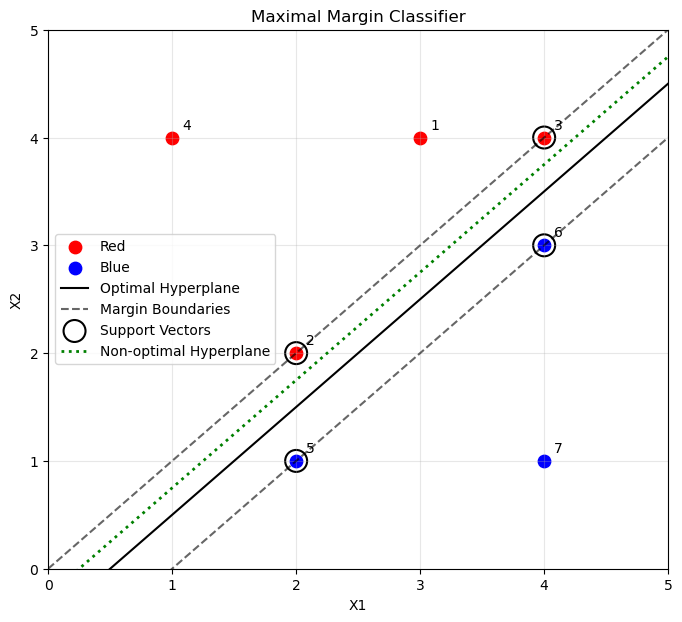

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Observations
red = np.array([[3, 4], [2, 2], [4, 4], [1, 4]])
blue = np.array([[2, 1], [4, 3], [4, 1]])

plt.figure(figsize=(8, 7))

# Plot observations
plt.scatter(red[:, 0], red[:, 1], color="red",
            s=80, label="Red")
plt.scatter(blue[:, 0], blue[:, 1], color="blue",
            s=80, label="Blue")

# Label observations
points = np.vstack([red, blue])
for i, (x1, x2) in enumerate(points):
    plt.annotate(str(i + 1), (x1 + 0.08, x2 + 0.08))

# Optimal separating hyperplane and margins
x = np.linspace(0, 5, 200)

plt.plot(x, x - 0.5, "k-",
         label="Optimal Hyperplane")
plt.plot(x, x, "k--", alpha=0.6,
         label="Margin Boundaries")
plt.plot(x, x - 1, "k--", alpha=0.6)

# Support vectors: observations 2, 3, 5, 6
support_vectors = np.array([
    [2, 2], [4, 4], [2, 1], [4, 3]
])

plt.scatter(
    support_vectors[:, 0],
    support_vectors[:, 1],
    s=250,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

# Non-optimal separating hyperplane
plt.plot(x, x - 0.25, "g:",
         linewidth=2,
         label="Non-optimal Hyperplane")

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Maximal Margin Classifier")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

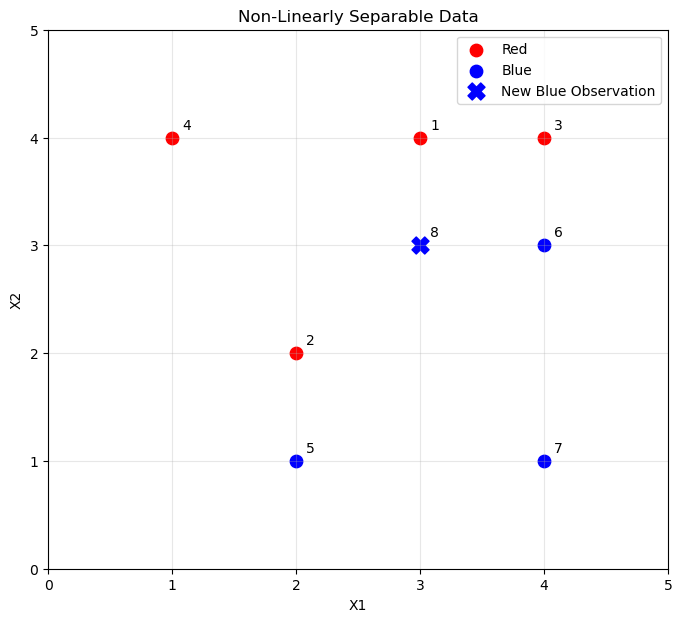

In [17]:
# Add a new blue observation at (3, 3)
new_blue = np.array([[3, 3]])

plt.figure(figsize=(8, 7))

plt.scatter(red[:, 0], red[:, 1],
            color="red", s=80, label="Red")

plt.scatter(blue[:, 0], blue[:, 1],
            color="blue", s=80, label="Blue")

plt.scatter(new_blue[:, 0], new_blue[:, 1],
            color="blue", marker="X", s=150,
            label="New Blue Observation")

# Label all observations
for i, (x1, x2) in enumerate(points):
    plt.annotate(str(i + 1), (x1 + 0.08, x2 + 0.08))

plt.annotate("8", (3.08, 3.08))

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Non-Linearly Separable Data")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**(a) Sketch the observations.**

The seven observations are plotted in the first figure. Four observations belong to the Red class, and three belong to the Blue class.

**(b) Sketch the optimal separating hyperplane and provide its equation.**

The optimal separating hyperplane is:

$$
X_2=X_1-0.5
$$

In standard hyperplane form:

$$
0.5-X_1+X_2=0
$$

This line separates all Red observations from Blue observations while maximizing the margin.

**(c) Describe the classification rule.**

The classification rule is:

$$
0.5-X_1+X_2>0 \Rightarrow \text{Red}
$$

Otherwise, classify the observation as Blue.

Therefore, the coefficients are:

$$
\beta_0=0.5,\quad \beta_1=-1,\quad \beta_2=1
$$

**(d) Indicate the margin for the maximal margin hyperplane.**

The two margin boundaries are:

$$
X_2=X_1
$$

and

$$
X_2=X_1-1
$$

The perpendicular distance from the optimal separating hyperplane to either margin boundary is:

$$
M=\frac{0.5}{\sqrt{(-1)^2+1^2}}
=\frac{1}{2\sqrt{2}}\approx0.354
$$

Therefore, the margin on each side of the hyperplane is approximately 0.354, and the total width between the two margin boundaries is approximately 0.707.

**(e) Indicate the support vectors.**

The support vectors are observations 2, 3, 5, and 6:

- Observation 2: (2, 2), Red
- Observation 3: (4, 4), Red
- Observation 5: (2, 1), Blue
- Observation 6: (4, 3), Blue

These observations lie directly on the margin boundaries and determine the optimal separating hyperplane.

**(f) Explain why a slight movement of observation 7 would not affect the hyperplane.**

Observation 7 is located at (4, 1), which is far from the margin boundaries. It is not a support vector.

Since the maximal margin hyperplane is determined by the support vectors, a slight movement of observation 7 would not change the optimal separating hyperplane, as long as it remains outside the margin.

**(g) Sketch a hyperplane that is not optimal and provide its equation.**

One possible non-optimal separating hyperplane is:

$$
X_2=X_1-0.25
$$

Equivalently:

$$
0.25-X_1+X_2=0
$$

This line correctly separates the two classes, but it is closer to the Red observations than the optimal hyperplane. Therefore, it has a smaller minimum margin and is not optimal.

**(h) Add an observation so that the data are no longer linearly separable.**

I added a new Blue observation at (3, 3).

This point lies exactly between the two Red observations (2, 2) and (4, 4). Because the new Blue observation is inside the convex hull of the Red class, no straight line can separate all Red observations from all Blue observations.

Therefore, the dataset is no longer linearly separable.
